# 05 · Classical FWI baseline + the hybrid (quantum misfit, classical search)

**Part A — classical baseline:** the paper's method (full-waveform inversion) in 2D on a laptop: true skull known,
brain starts uniform, invert transcranial data, look for the bleed (mirrors the paper's Fig. 8 test).
Gradients come from JAX autodiff (equivalent to the adjoint-state method the paper uses).

**Part B — hybrid:** on a tiny 3D head (7×7×7, **11 qubits** in the compact encoding) a quantum computer supplies one
number per guess — the mismatch between predicted and measured transducer energies — and a classical loop picks the
best bleed location. We measure how many shots the quantum read-out needs.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))   # so `import qwave` works from notebooks/
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
RESULTS = pathlib.Path.cwd().parent / "results"; RESULTS.mkdir(exist_ok=True)
from qwave.fwi import make_problem, simulate_all, invert
P = make_problem()          # 104×104 grid (2.5 mm cells), 32 transducers, 60 kHz pulse
print("grid", P["c_true"].shape, "time steps", P["nt"])
data = simulate_all(P, P["c_true"])
c_est, hist = invert(P, data, iters=40, batch=8, lr=3.0)

grid (104, 104) time steps 776


iter   1  misfit 1.943e-05


iter  10  misfit 3.139e-05


iter  20  misfit 1.091e-05


iter  30  misfit 3.330e-06


iter  40  misfit 1.298e-06


bleed: true 1578.0 m/s, recovered 1576.3; surrounding brain recovered 1546.3


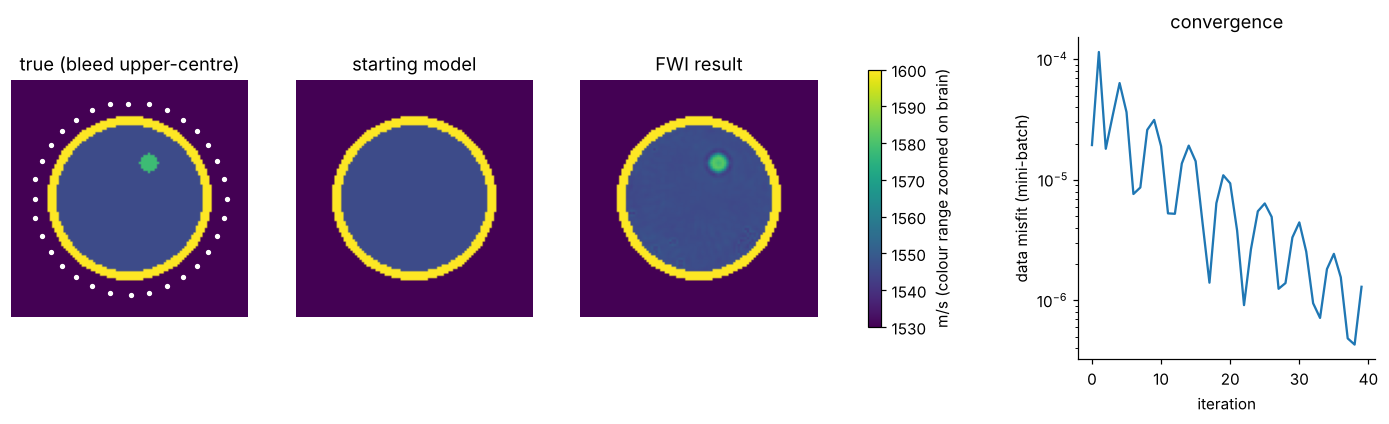

In [2]:
b = P["lab"] == 4; br = P["lab"] == 3
print(f"bleed: true {P['c_true'][b].mean():.1f} m/s, recovered {c_est[b].mean():.1f}; surrounding brain recovered {c_est[br].mean():.1f}")
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for a, arr, t in zip(ax[:3], [P["c_true"], P["c0"], c_est], ["true (bleed upper-centre)", "starting model", "FWI result"]):
    im = a.imshow(arr, cmap="viridis", vmin=1530, vmax=1600); a.set_title(t); a.axis("off")
a = ax[0]; a.scatter(P["trans"][:, 1], P["trans"][:, 0], s=6, c="w")
fig.colorbar(im, ax=ax[:3], shrink=0.8, label="m/s (colour range zoomed on brain)")
ax[3].semilogy(hist); ax[3].set(xlabel="iteration", ylabel="data misfit (mini-batch)", title="convergence")
plt.savefig(RESULTS / "05_fwi.png", bbox_inches="tight"); plt.show()

## Part B — hybrid: quantum read-out of the misfit, classical choice of bleed location

In [3]:
from qwave.hybrid import setup, run_trials, run_detection
from qwave.resources import ibm_qpu_seconds
H = setup((7, 7, 7))
print(f"{H['qubits']} qubits (compact encoding), {len(H['cands'])} candidate models, {len(H['rx'])} transducer cubes, true bleed at {H['true']}")
shots_list = (10**6, 10**8, 10**9, 10**10, 10**11)
loc = run_trials(H, shots_list=shots_list, trials=20)
print("exact (infinite shots) picks the right location:", loc["exact_pick_correct"])
for S in shots_list:
    qpu = ibm_qpu_seconds(S * len(H["times"]) * len(H["cands"]))
    print(f"shots per circuit {S:.0e}: success {loc['success'][S]:.0%}   (QPU time for one search ≈ {qpu/86400:.1f} days)")

11 qubits (compact encoding), 20 candidate models, 97 transducer cubes, true bleed at (np.int64(3), np.int64(3), np.int64(4))


exact (infinite shots) picks the right location: True
shots per circuit 1e+06: success 0%   (QPU time for one search ≈ 0.2 days)
shots per circuit 1e+08: success 5%   (QPU time for one search ≈ 24.3 days)
shots per circuit 1e+09: success 5%   (QPU time for one search ≈ 243.1 days)
shots per circuit 1e+10: success 50%   (QPU time for one search ≈ 2430.6 days)
shots per circuit 1e+11: success 95%   (QPU time for one search ≈ 24305.6 days)


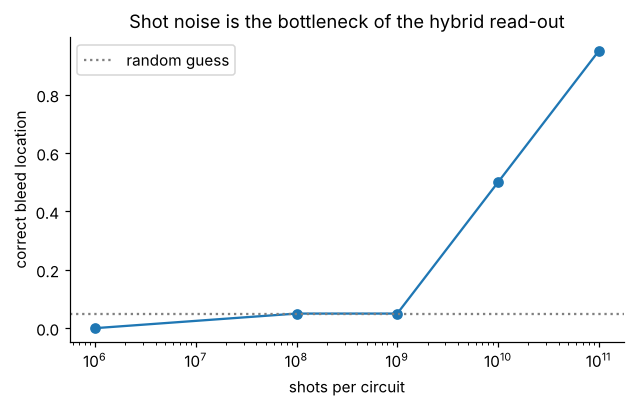

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.semilogx(shots_list, [loc["success"][S] for S in shots_list], "o-")
ax.axhline(1 / len(H["cands"]), color="gray", ls=":", label="random guess")
ax.set(xlabel="shots per circuit", ylabel="correct bleed location", title="Shot noise is the bottleneck of the hybrid read-out")
ax.legend(); plt.savefig(RESULTS / "05_hybrid_shots.png", bbox_inches="tight"); plt.show()

**Takeaways**
* Classical FWI on a laptop finds the 2% bleed in 2D in seconds; the paper's 3D version needs a cluster/GPUs, which the
  authors expect to reach < 10 min.
* The hybrid works *in principle* — with enough shots the quantum misfit finds the right location — but a single-cube,
  2%-contrast bleed needs ~10¹⁰–10¹¹ shots per circuit, i.e. months to years of today's QPU time.
* So the honest recommendation: **quantum is not a fit for this pipeline yet.** What would change it: fault-tolerant
  hardware for the compact encoding, much faster shot rates, and questions designed to need very few numbers.